# Paso 5: XGBoost y explicabilidad (SHAP)

Este cuaderno hace dos cosas:

1. **XGBoost**, el modelo clásico más fuerte para datos en tabla. Si aun así pierde contra la CNN, tu conclusión queda blindada frente a un revisor que pregunte "¿y si probaban un modelo clásico mejor?".
2. **Explicabilidad**: qué mira cada modelo para decidir.
   - Para XGBoost se usa SHAP directamente (TreeExplainer), que es exacto para modelos de árboles.
   - Para la CNN se usan **gradientes esperados**, la aproximación de los valores SHAP que se usa en redes neuronales. Produce un mapa de qué zona del latido pesó más en la decisión.

**Antes de ejecutar:** activa la **T4 GPU**. Tarda unos 20 minutos.

Al final se descargan las figuras a 300 DPI, que es la resolución que exige Tecnura.

## 1. Instalar y descargar datos

In [ ]:
!pip install wfdb xgboost shap -q
import wfdb, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from sklearn.metrics import f1_score, recall_score, precision_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

wfdb.dl_database('mitdb', dl_dir='mitdb')
print('Descarga lista')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.6 MB/s eta 0:00:00
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list f

## 2. Preparar los latidos (igual que siempre)

In [ ]:
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
AAMI = {'N':'N','L':'N','R':'N','e':'N','j':'N','A':'S','a':'S','J':'S','S':'S','V':'V','E':'V','F':'F'}
CODIGOS_LATIDO = set('NLRejAaJSVEF/fQ')
CLASES = ['N','S','V','F']
FS, ANTES, DESPUES = 360, 90, 162

def filtro_pasa_altas(x, fs=FS, fc=1.0):
    alpha = np.exp(-2*np.pi*fc/fs)
    return x - lfilter([1-alpha], [1, -alpha], x)

def extraer_latidos(num):
    ruta = f'mitdb/{num}'
    rec = wfdb.rdrecord(ruta); ann = wfdb.rdann(ruta, 'atr')
    canal = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    x = filtro_pasa_altas(rec.p_signal[:, canal]); x = (x - x.mean())/x.std()
    pos = np.array([p for p, s in zip(ann.sample, ann.symbol) if s in CODIGOS_LATIDO])
    sim = [s for s in ann.symbol if s in CODIGOS_LATIDO]
    rr = np.diff(pos)/FS; rr_medio = rr.mean()
    V, R, Y = [], [], []
    for i in range(1, len(pos)-1):
        if sim[i] not in AAMI: continue
        r = pos[i]
        if r-ANTES < 0 or r+DESPUES > len(x): continue
        V.append(x[r-ANTES:r+DESPUES])
        R.append([rr[i-1], rr[i], rr[max(0,i-10):i].mean(), rr[i-1]/rr_medio, rr[i]/rr_medio])
        Y.append(AAMI[sim[i]])
    return V, R, Y

def construir(lista):
    V, R, Y = [], [], []
    for n in lista:
        v, r, y = extraer_latidos(n); V += v; R += r; Y += y
    return np.array(V), np.array(R), np.array(Y)

V_ent, R_ent, y_ent = construir(DS1)
V_pru, R_pru, y_pru = construir(DS2)
a_numero = {c:i for i,c in enumerate(CLASES)}
y_ent_num = np.array([a_numero[c] for c in y_ent])
y_pru_num = np.array([a_numero[c] for c in y_pru])

NOMBRES = ['RR_prev', 'RR_next', 'RR_local', 'RR_prev/RR_mean', 'RR_next/RR_mean'] + \
          [f'sample_{i}' for i in range(0, 252, 10)]
X_ent = np.hstack([R_ent, V_ent[:, ::10]])
X_pru = np.hstack([R_pru, V_pru[:, ::10]])
print('Listo. Latidos de prueba:', len(y_pru_num), '| caracteristicas:', X_ent.shape[1])

Listo. Latidos de prueba: 49661 | caracteristicas: 31


## 3. XGBoost (5 ejecuciones)

In [ ]:
from xgboost import XGBClassifier

pesos_v = compute_class_weight('balanced', classes=np.arange(4), y=y_ent_num)
peso_muestra = pesos_v[y_ent_num]

filas = []
for s in [0,1,2,3,4]:
    modelo_xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                               tree_method='hist', objective='multi:softprob',
                               num_class=4, random_state=s, n_jobs=-1)
    modelo_xgb.fit(X_ent, y_ent_num, sample_weight=peso_muestra)
    inicio = time.time(); pred = modelo_xgb.predict(X_pru)
    ms = (time.time()-inicio)*1000/len(X_pru)
    se = recall_score(y_pru_num, pred, labels=range(4), average=None, zero_division=0)
    pp = precision_score(y_pru_num, pred, labels=range(4), average=None, zero_division=0)
    f1 = f1_score(y_pru_num, pred, labels=range(4), average='macro', zero_division=0)
    fila = {'semilla': s, 'F1_macro': f1, 'ms_por_latido': ms}
    for i,c in enumerate(CLASES): fila[f'Se_{c}'] = se[i]; fila[f'+P_{c}'] = pp[i]
    filas.append(fila); print(f'  semilla {s}: F1 macro = {f1:.3f}')

df_xgb = pd.DataFrame(filas)
print()
print('XGBoost — promedio de 5 ejecuciones:')
for c in ['F1_macro'] + [f'Se_{k}' for k in CLASES] + [f'+P_{k}' for k in CLASES]:
    print(f'  {c}: {df_xgb[c].mean():.3f} ± {df_xgb[c].std():.3f}')
print('  ms por latido:', round(df_xgb["ms_por_latido"].mean(), 4))
df_xgb.to_csv('resultados_xgboost.csv', index=False)
print()
print('Matriz de confusion (ultima ejecucion):'); print(confusion_matrix(y_pru_num, pred, labels=range(4)))
pred_xgb = pred

  semilla 0: F1 macro = 0.509
  semilla 1: F1 macro = 0.509
  semilla 2: F1 macro = 0.509
  semilla 3: F1 macro = 0.509
  semilla 4: F1 macro = 0.509

XGBoost — promedio de 5 ejecuciones:
  F1_macro: 0.509 ± 0.000
  Se_N: 0.928 ± 0.000
  Se_S: 0.154 ± 0.000
  Se_V: 0.909 ± 0.000
  Se_F: 0.139 ± 0.000
  +P_N: 0.959 ± 0.000
  +P_S: 0.310 ± 0.000
  +P_V: 0.792 ± 0.000
  +P_F: 0.024 ± 0.000
  ms por latido: 0.0203

Matriz de confusion (ultima ejecucion):
[[41017   588   446  2167]
 [ 1252   282   298     4]
 [  211    37  2926    45]
 [  307     2    25    54]]


In [ ]:
print('Nodos totales:', len(modelo_xgb.get_booster().trees_to_dataframe()))

Nodos totales: 64460


## 4. SHAP sobre XGBoost

Cada punto es un latido. A la derecha, las características que empujan hacia esa clase; a la izquierda, las que empujan en contra. El color indica si el valor de la característica era alto o bajo.

**Qué mirar:** si para la clase S aparecen arriba las medidas RR (sobre todo el intervalo anterior), significa que el modelo reconoce esos latidos porque **llegan antes de tiempo**, que es exactamente el criterio fisiológico. Eso es lo que se escribe en el artículo.

/tmp/ipykernel_1040/3654833929.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES,


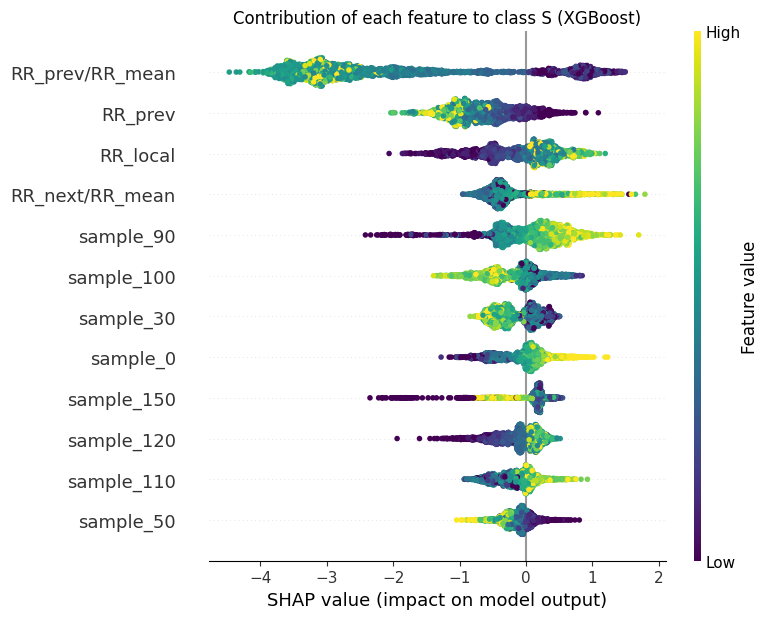

/tmp/ipykernel_1040/3654833929.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES,


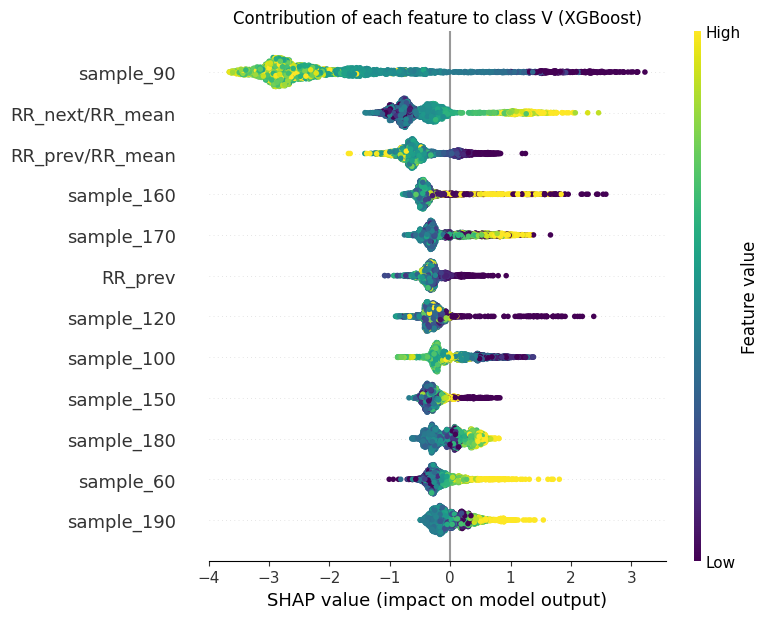

In [ ]:
import shap

explicador = shap.TreeExplainer(modelo_xgb)
np.random.seed(0)
muestra = np.random.choice(len(X_pru), 3000, replace=False)
X_m = X_pru[muestra]
sv = explicador.shap_values(X_m)

def shap_de_clase(sv, idx):
    return sv[idx] if isinstance(sv, list) else sv[:, :, idx]

for c in ['S', 'V']:
    i = a_numero[c]
    plt.figure()
    shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES,
                      max_display=12, show=False,
                      cmap=plt.get_cmap('viridis'))
    plt.title(f'Contribution of each feature to class {c} (XGBoost)')
    plt.tight_layout()
    plt.savefig(f'shap_xgboost_clase_{c}.png', dpi=300, bbox_inches='tight')
    plt.show()

### Gráficas SHAP de XGBoost en Español

/tmp/ipykernel_1040/1783292811.py:48: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES_ES,


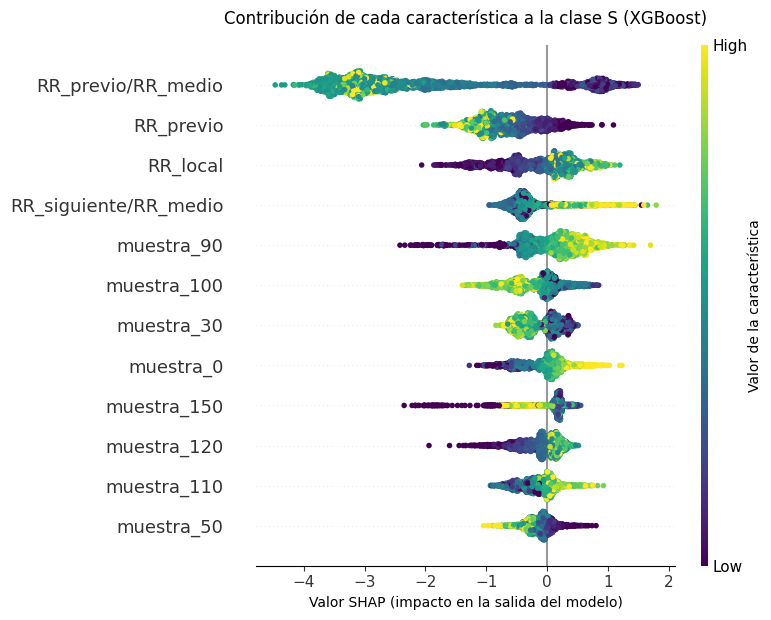

/tmp/ipykernel_1040/1783292811.py:48: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES_ES,


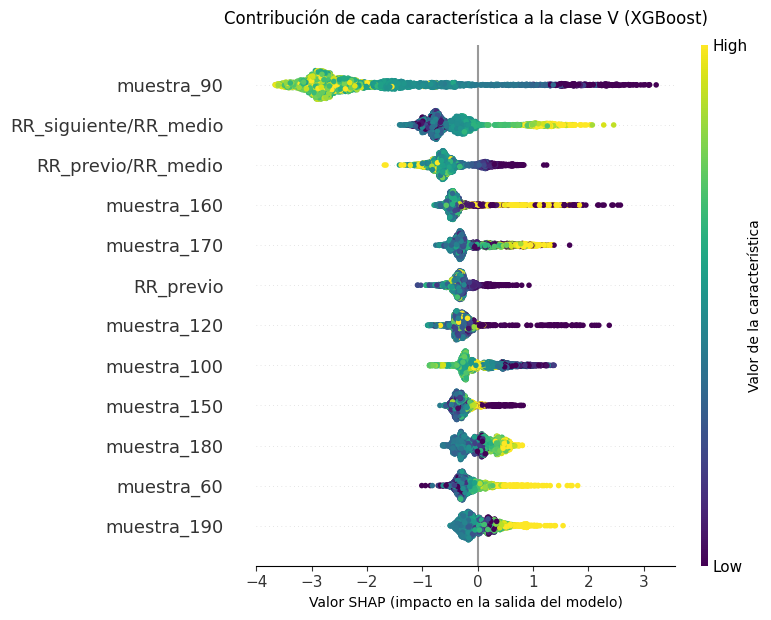

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Forzar la carga de datos si el estado del kernel se perdió
try:
    _ = X_ent
except NameError:
    print("Estado ausente. Preparando datos rápidamente...")
    V_ent, R_ent, y_ent = construir(DS1)
    V_pru, R_pru, y_pru = construir(DS2)
    a_numero = {c:i for i,c in enumerate(CLASES)}
    y_ent_num = np.array([a_numero[c] for c in y_ent])
    y_pru_num = np.array([a_numero[c] for c in y_pru])
    X_ent = np.hstack([R_ent, V_ent[:, ::10]])
    X_pru = np.hstack([R_pru, V_pru[:, ::10]])
    from sklearn.utils.class_weight import compute_class_weight
    pesos_v = compute_class_weight('balanced', classes=np.arange(4), y=y_ent_num)
    peso_muestra = pesos_v[y_ent_num]

a_numero = {'N': 0, 'S': 1, 'V': 2, 'F': 3}
modelo_a_usar = modelo_xgb if 'modelo_xgb' in globals() else (m if 'm' in globals() else None)

if modelo_a_usar is None:
    print("Re-entrenando XGBoost para generar las gráficas...")
    from xgboost import XGBClassifier
    modelo_a_usar = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                                  objective='multi:softprob', num_class=4, random_state=0, n_jobs=-1)
    modelo_a_usar.fit(X_ent, y_ent_num, sample_weight=peso_muestra)

NOMBRES_ES = [
    'RR_previo', 'RR_siguiente', 'RR_local', 'RR_previo/RR_medio', 'RR_siguiente/RR_medio'
] + [f'muestra_{i}' for i in range(0, 252, 10)]

explicador = shap.TreeExplainer(modelo_a_usar)
np.random.seed(0)
muestra = np.random.choice(len(X_pru), 3000, replace=False)
X_m = X_pru[muestra]
sv = explicador.shap_values(X_m)

def shap_de_clase(sv, idx):
    return sv[idx] if isinstance(sv, list) else sv[:, :, idx]

for c in ['S', 'V']:
    i = a_numero[c]
    plt.figure()
    shap.summary_plot(shap_de_clase(sv, i), X_m, feature_names=NOMBRES_ES,
                      max_display=12, show=False,
                      cmap=plt.get_cmap('viridis'))

    plt.title(f'Contribución de cada característica a la clase {c} (XGBoost)', fontsize=12, pad=15)
    plt.xlabel('Valor SHAP (impacto en la salida del modelo)', fontsize=10)

    fig = plt.gcf()
    for ax in fig.axes:
        if ax.get_ylabel() == 'Feature value':
            ax.set_ylabel('Valor de la característica', fontsize=10)

    plt.tight_layout()
    plt.savefig(f'shap_xgboost_clase_{c}_es.png', dpi=300, bbox_inches='tight')
    plt.show()

## 5. Entrenar la CNN (el modelo ganador)

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

V_tr, V_val, R_tr, R_val, y_tr, y_val = train_test_split(
    V_ent, R_ent, y_ent_num, test_size=0.1, stratify=y_ent_num, random_state=42)
pesos_clase = {i: w for i, w in enumerate(compute_class_weight('balanced', classes=np.arange(4), y=y_tr))}

keras.utils.set_random_seed(0)
entrada_forma = keras.Input(shape=(252,1))
x = layers.Conv1D(32, 7, activation='relu', padding='same')(entrada_forma)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(64, 5, activation='relu', padding='same')(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(64, 3, activation='relu', padding='same')(x)
x = layers.GlobalAveragePooling1D()(x)
entrada_rr = keras.Input(shape=(5,))
z = layers.concatenate([x, entrada_rr])
z = layers.Dense(64, activation='relu')(z)
z = layers.Dropout(0.3)(z)
salida = layers.Dense(4, activation='softmax')(z)
cnn = keras.Model([entrada_forma, entrada_rr], salida)
cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.fit([V_tr[...,None], R_tr], y_tr, validation_data=([V_val[...,None], R_val], y_val),
        epochs=40, batch_size=256, class_weight=pesos_clase,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)],
        verbose=0)
pred_cnn = cnn.predict([V_pru[...,None], R_pru], verbose=0).argmax(axis=1)
print('CNN entrenada. F1 macro =',
      round(f1_score(y_pru_num, pred_cnn, labels=range(4), average='macro', zero_division=0), 3))

CNN entrenada. F1 macro = 0.595


## 6. Explicabilidad de la CNN: ¿qué parte del latido mira?

Se promedian las atribuciones de 150 latidos bien clasificados de cada clase. La gráfica de arriba es el latido promedio; la de abajo, cuánto pesó cada punto en la decisión.

**Qué mirar:** si el pico de importancia coincide con el complejo QRS en la clase V, la red está mirando lo mismo que miraría un especialista. Si la importancia está repartida al azar, no.

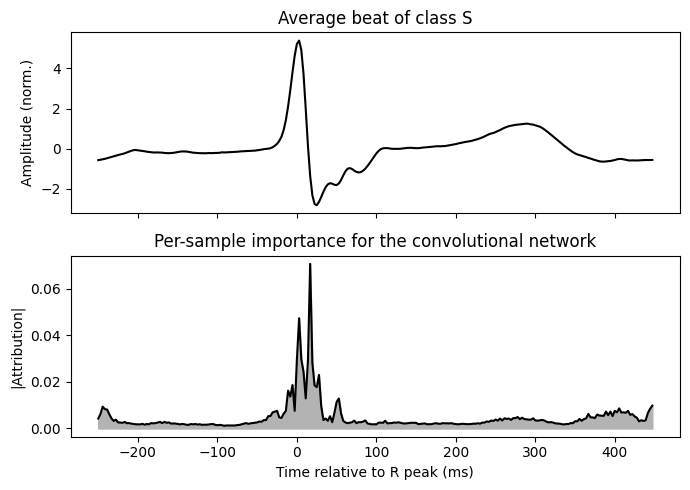

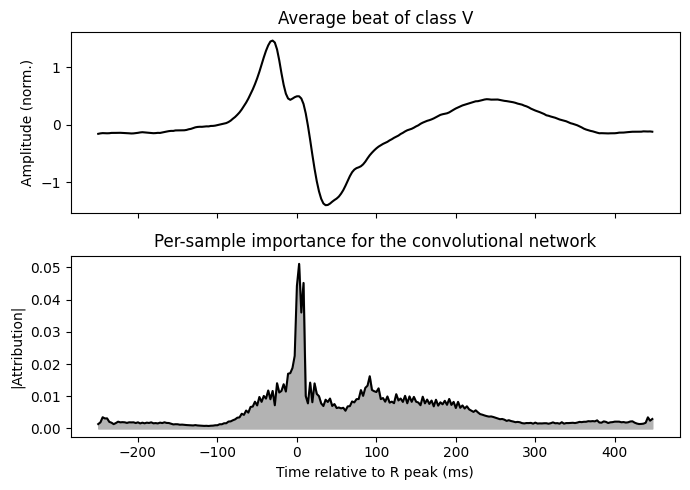

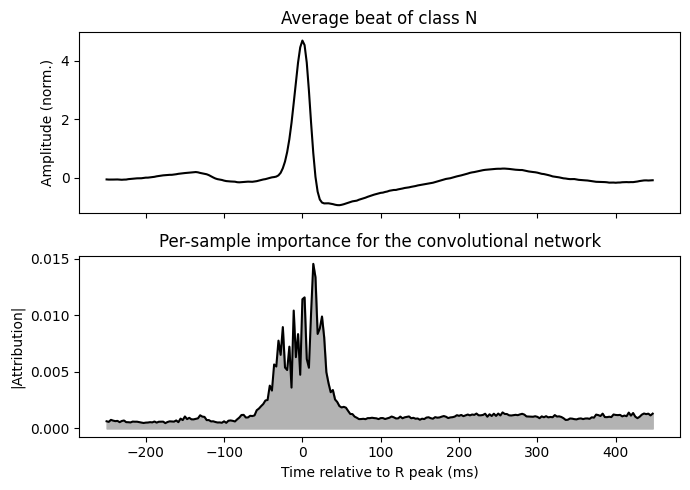

Importancia media de las medidas RR (|atribucion|):
                      S       V       N
RR_prev          0.0604  0.0946  0.0448
RR_next          0.0755  0.0165  0.0080
RR_local         0.0364  0.0095  0.0054
RR_prev/RR_mean  0.2492  0.0667  0.0351
RR_next/RR_mean  0.0530  0.0512  0.0114


In [ ]:
# Gradientes esperados: aproximacion de los valores SHAP para redes neuronales.
# Se compara el latido con muchas referencias tomadas del propio conjunto de entrenamiento.
rng = np.random.default_rng(0)

def atribuciones(f, r, clase, n=64):
    idx = rng.integers(0, len(V_tr), n)
    base_f = V_tr[idx][..., None].astype('float32')
    base_r = R_tr[idx].astype('float32')
    f_b = np.repeat(f[None, :, None], n, axis=0).astype('float32')
    r_b = np.repeat(r[None, :], n, axis=0).astype('float32')
    alfa = rng.random((n,1,1)).astype('float32')
    tf_f = tf.Variable(base_f + alfa*(f_b - base_f))
    tf_r = tf.Variable(base_r + alfa[:,:,0]*(r_b - base_r))
    with tf.GradientTape() as cinta:
        cinta.watch([tf_f, tf_r])
        y = cnn([tf_f, tf_r])[:, clase]
    gf, gr = cinta.gradient(y, [tf_f, tf_r])
    a_f = np.mean(gf.numpy()[:,:,0] * (f_b - base_f)[:,:,0], axis=0)
    a_r = np.mean(gr.numpy() * (r_b - base_r), axis=0)
    return a_f, a_r

resumen_rr = {}
for c in ['S','V','N']:
    i = a_numero[c]
    ejemplos = np.where((y_pru_num == i) & (pred_cnn == i))[0]
    ejemplos = rng.choice(ejemplos, min(150, len(ejemplos)), replace=False)
    A_f = np.zeros(252); A_r = np.zeros(5)
    for k in ejemplos:
        af, ar = atribuciones(V_pru[k], R_pru[k], i)
        A_f += np.abs(af); A_r += np.abs(ar)
    A_f /= len(ejemplos); A_r /= len(ejemplos)
    resumen_rr[c] = A_r

    t = (np.arange(252) - ANTES) / FS * 1000
    fig, ax = plt.subplots(2, 1, figsize=(7,5), sharex=True)
    ax[0].plot(t, V_pru[ejemplos].mean(axis=0), color='k')
    ax[0].set_ylabel('Amplitude (norm.)')
    ax[0].set_title(f'Average beat of class {c}')
    ax[1].plot(t, A_f, color='k')
    ax[1].fill_between(t, 0, A_f, color='0.7')
    ax[1].set_ylabel('|Attribution|')
    ax[1].set_xlabel('Time relative to R peak (ms)')
    ax[1].set_title('Per-sample importance for the convolutional network')
    plt.tight_layout(); plt.savefig(f'shap_cnn_clase_{c}.png', dpi=300, bbox_inches='tight'); plt.show()

print('Importancia media de las medidas RR (|atribucion|):')
print(pd.DataFrame(resumen_rr, index=NOMBRES[:5]).round(4))

### Gráficas de Atribución (CNN) en Español

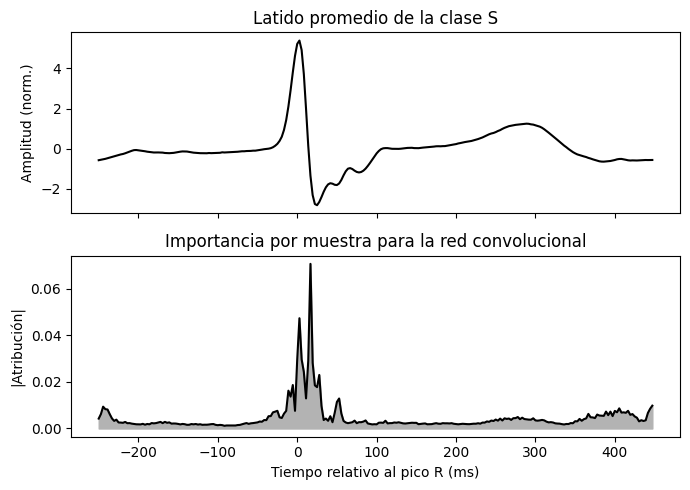

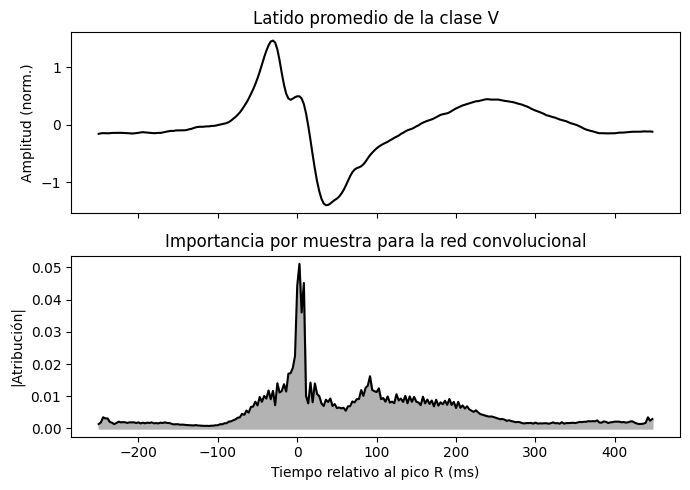

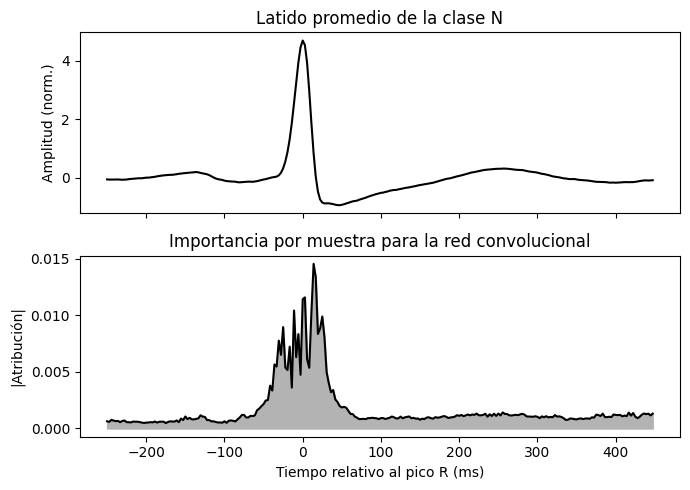

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Forzar la carga de datos y variables de soporte si se perdió el estado
try:
    _ = y_pru_num
except NameError:
    print("Estado ausente. Preparando datos para la visualización de la CNN...")
    V_ent, R_ent, y_ent = construir(DS1)
    V_pru, R_pru, y_pru = construir(DS2)
    a_numero = {c:i for i,c in enumerate(CLASES)}
    y_ent_num = np.array([a_numero[c] for c in y_ent])
    y_pru_num = np.array([a_numero[c] for c in y_pru])

a_numero = {'N': 0, 'S': 1, 'V': 2, 'F': 3}
rng = np.random.default_rng(0)

resumen_rr = {}
for c in ['S','V','N']:
    i = a_numero[c]
    ejemplos = np.where((y_pru_num == i) & (pred_cnn == i))[0]
    ejemplos = rng.choice(ejemplos, min(150, len(ejemplos)), replace=False)
    A_f = np.zeros(252); A_r = np.zeros(5)
    for k in ejemplos:
        af, ar = atribuciones(V_pru[k], R_pru[k], i)
        A_f += np.abs(af); A_r += np.abs(ar)
    A_f /= len(ejemplos); A_r /= len(ejemplos)
    resumen_rr[c] = A_r

    t = (np.arange(252) - ANTES) / FS * 1000
    fig, ax = plt.subplots(2, 1, figsize=(7,5), sharex=True)

    ax[0].plot(t, V_pru[ejemplos].mean(axis=0), color='k')
    ax[0].set_ylabel('Amplitud (norm.)')
    ax[0].set_title(f'Latido promedio de la clase {c}')

    ax[1].plot(t, A_f, color='k')
    ax[1].fill_between(t, 0, A_f, color='0.7')
    ax[1].set_ylabel('|Atribución|')
    ax[1].set_xlabel('Tiempo relativo al pico R (ms)')
    ax[1].set_title('Importancia por muestra para la red convolucional')

    plt.tight_layout()
    plt.savefig(f'shap_cnn_clase_{c}_es.png', dpi=300, bbox_inches='tight')
    plt.show()

## 7. Descargar resultados y figuras

In [ ]:
from google.colab import files
import glob
for f in ['resultados_xgboost.csv'] + sorted(glob.glob('shap_*.png')):
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import glob

# Descargar las nuevas versiones en español
archivos_es = glob.glob('shap_*_es.png')
for f in archivos_es:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shap
from xgboost import XGBClassifier

m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                  objective='multi:softprob', num_class=4, random_state=0, n_jobs=-1)
m.fit(X_ent, y_ent_num, sample_weight=peso_muestra)

NOMBRES = ['RR_prev', 'RR_next', 'RR_local', 'RR_prev/RR_mean', 'RR_next/RR_mean'] + \
          [f'sample_{i}' for i in range(0, 252, 10)]

exp = shap.TreeExplainer(m)
rng = np.random.default_rng(0)
idx = rng.choice(len(X_pru), 3000, replace=False)
sv = exp.shap_values(X_pru[idx])

def de_clase(sv, i):
    return sv[i] if isinstance(sv, list) else sv[:, :, i]

for c in ['S', 'V']:
    i = a_numero[c]
    imp = np.abs(de_clase(sv, i)).mean(0)
    orden = np.argsort(imp)[::-1][:12]
    print(f'Clase {c}, doce caracteristicas mas influyentes:')
    for k, j in enumerate(orden, 1):
        print(f'  {k:2d}. {NOMBRES[j]:18s} {imp[j]:.4f}')
    print()

Clase S, doce caracteristicas mas influyentes:
   1. RR_prev/RR_mean    2.3777
   2. RR_prev            0.6580
   3. RR_local           0.4720
   4. RR_next/RR_mean    0.4349
   5. sample_90          0.4214
   6. sample_100         0.3141
   7. sample_30          0.2867
   8. sample_0           0.2674
   9. sample_150         0.2653
  10. sample_120         0.2451
  11. sample_110         0.2403
  12. sample_50          0.1835

Clase V, doce caracteristicas mas influyentes:
   1. sample_90          2.2278
   2. RR_next/RR_mean    0.6571
   3. RR_prev/RR_mean    0.5576
   4. sample_160         0.4548
   5. sample_170         0.3852
   6. RR_prev            0.3294
   7. sample_100         0.3192
   8. sample_120         0.3182
   9. sample_150         0.3110
  10. sample_60          0.2676
  11. sample_180         0.2675
  12. sample_190         0.2380

